# 06_03 — Lag study: BTV0125 classic parameters vs charge

Does any of the classic screen parameters from notebook 04 (amplitude, intensity, mean x/y, sigma x/y) correlate better
with the charge (`BCM_GUN`) when shifted in time by up to ±5 shots? Features are read from `outputs/btv0125_params.csv` (run notebook 04 first).

- **Convention:** rows as recorded. For lag *L* we correlate `feature[i + L]` with `BCM_GUN[i]`;
  a peak at **L = 0** means the camera and the charge monitor are stored in the same row.
- **overall** r uses the raw values (includes the slow drift); **shot-to-shot** r removes a 51-shot rolling mean first.
- The frozen camera shot (repeated image) is left out. Noise level for ~2100 shots: |r| ≲ 0.07.

In [1]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
OUT_DIR = DATA_DIR.parent / "outputs"
files = sorted(DATA_DIR.glob("chunk_*.h5"))

LAGS = np.arange(-5, 6)
SERIES = ["#2a78d6", "#eb6834"]  # overall, shot-to-shot
MUTED = "#8a8985"

charge = pd.Series(np.concatenate([h5py.File(path, "r")["BCM_GUN"][:] for path in files]), name="BCM_GUN")
btv = pd.read_csv(OUT_DIR / "btv0125_params.csv", index_col="shot")
features = btv[["amplitude", "intensity", "mean_x", "mean_y", "sigma_x", "sigma_y"]].copy()
features[btv["frozen"]] = np.nan
print(f"{features.shape[1]} features: {list(features.columns)}")
print(f"{len(features)} shots, {features.isna().all(axis=1).sum()} frozen camera shot(s) left out")

6 features: ['amplitude', 'intensity', 'mean_x', 'mean_y', 'sigma_x', 'sigma_y']
2100 shots, 1 frozen camera shot(s) left out


In [2]:
def detrend(x, k=51):
    return x - x.rolling(k, center=True, min_periods=1).mean()


r = {
    kind: pd.DataFrame({
        lag: [c.corr(f.shift(-lag)) for f in (feats[col] for col in features.columns)]
        for lag in LAGS
    }, index=features.columns).rename_axis(columns="lag")
    for kind, c, feats in [("overall", charge, features), ("shot-to-shot", detrend(charge), features.apply(detrend))]
}
best = r["shot-to-shot"].abs().idxmax(axis=1)
pd.DataFrame({
    "best lag": best,
    "r at best lag": [r["shot-to-shot"].loc[f, best[f]] for f in features.columns],
    "r at lag 0": r["shot-to-shot"][0],
    "r at lag +1": r["shot-to-shot"][1],
}).round(3)

,best lag,r at best lag,r at lag 0,r at lag +1
amplitude,0,0.344,0.344,0.099
intensity,0,0.790,0.790,0.111
mean_x,0,-0.118,-0.118,-0.049
mean_y,0,0.186,0.186,0.060
sigma_x,0,0.124,0.124,-0.005
sigma_y,0,0.143,0.143,-0.019


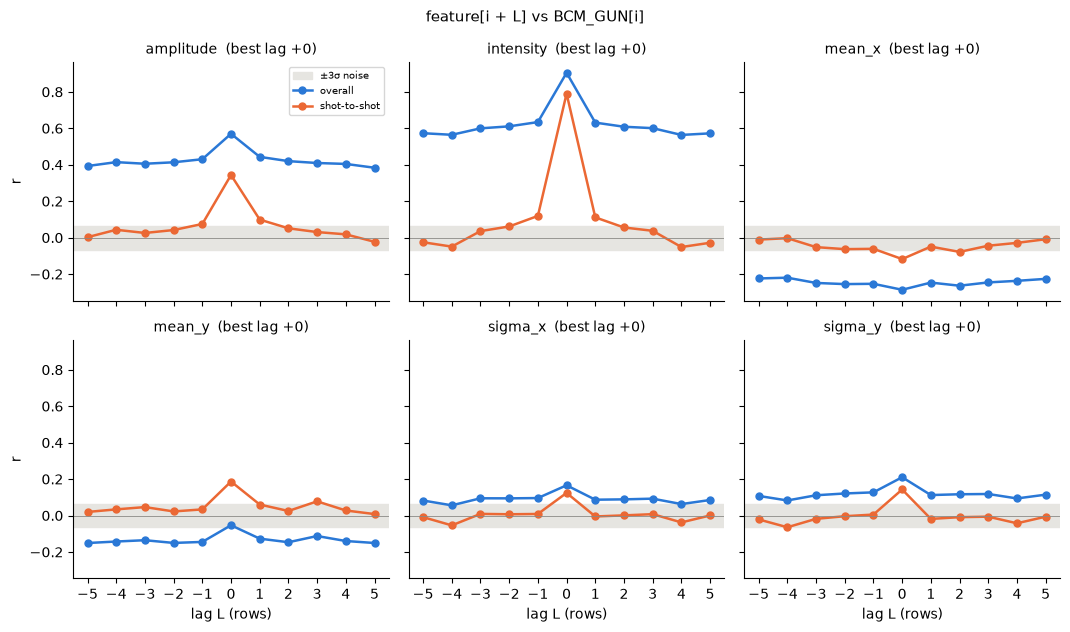

In [3]:
noise = 3 / np.sqrt(features.notna().all(axis=1).sum())
NCOLS = 3
nrows = int(np.ceil(features.shape[1] / NCOLS))

fig, axes = plt.subplots(nrows, NCOLS, figsize=(3.6 * NCOLS, 3.2 * nrows), sharex=True, sharey=True, squeeze=False)
for ax, f in zip(axes.ravel(), features.columns):
    ax.axhspan(-noise, noise, color="#e6e5e1", label="±3σ noise")
    for color, kind in zip(SERIES, r):
        ax.plot(LAGS, r[kind].loc[f], "o-", color=color, lw=1.8, ms=5, label=kind)
    ax.axhline(0, color=MUTED, lw=0.6)
    ax.set_title(f"{f}  (best lag {best[f]:+d})", fontsize=10)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
for ax in axes.ravel()[features.shape[1]:]:
    ax.set_visible(False)
for ax in axes[-1]:
    ax.set(xticks=LAGS, xlabel="lag L (rows)")
for ax in axes[:, 0]:
    ax.set_ylabel("r")
axes[0, 0].legend(fontsize=7)
fig.suptitle("feature[i + L] vs BCM_GUN[i]", fontsize=11)
fig.tight_layout()

## Scatter of the feature most correlated with the charge: no shift vs its best shift

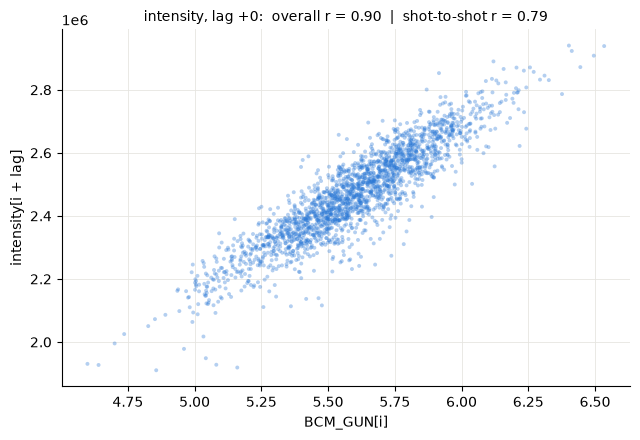

In [4]:
top = r["shot-to-shot"].abs().max(axis=1).idxmax()
lags_to_show = [0] if best[top] == 0 else [0, best[top]]

fig, axes = plt.subplots(1, len(lags_to_show), figsize=(6.5 * len(lags_to_show), 4.5), sharey=True, squeeze=False)
for ax, lag in zip(axes[0], lags_to_show):
    ax.scatter(charge, features[top].shift(-lag), s=8, color=SERIES[0], alpha=0.35, edgecolors="none")
    ax.set(xlabel="BCM_GUN[i]", title=f"{top}, lag {lag:+d}:  overall r = {r['overall'].loc[top, lag]:.2f}  |  "
                                        f"shot-to-shot r = {r['shot-to-shot'].loc[top, lag]:.2f}")
    ax.title.set_fontsize(10)
    ax.grid(color="#e6e5e1", lw=0.6)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
axes[0, 0].set_ylabel(f"{top}[i + lag]")
fig.tight_layout()